Saving LDA_Dataset.csv to LDA_Dataset.csv
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6    Class
0   2.665675   1.019702   0.474698  -3.723351  -1.686231   2.455737  Class_A
1   2.205112  -4.060952   2.157308   2.261413   0.479444   3.549782  Class_B
2   0.951933   1.490185  -1.024187  -2.090485  -0.468948  -0.674708  Class_C
3   4.805042   2.695314  -1.484898  -3.500672  -2.296602   1.343669  Class_A
4  -1.154440   0.405701   0.817766   0.705357   3.607272   1.352961  Class_A
5   3.419831   1.993340   0.529693  -3.084467  -0.886804   1.265844  Class_A
6   0.203571  -1.385217   0.586364   2.462011   2.412413  -0.983078  Class_B
7   1.263865  -3.293013   0.307407   3.185462   2.718337   0.297723  Class_B
8   1.991466  -3.079682   0.057013  -0.653363   2.955657   1.327113  Class_B
9   1.721758  -1.000312  -0.193659  -2.101795  -2.584006   1.519436  Class_C
Shape: (240, 7)
Columns: Index(['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5',
       'Featur

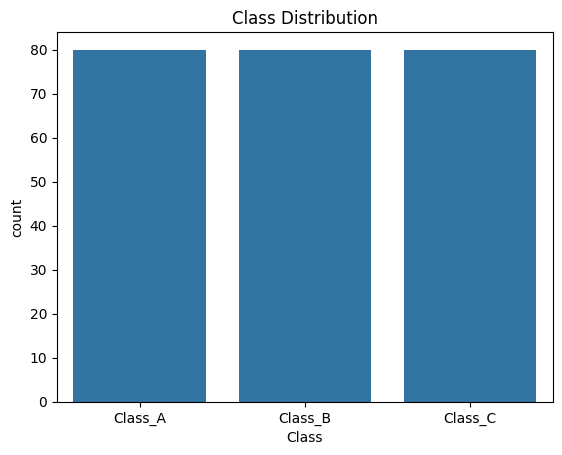

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from google.colab import files
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print(df.head(10))
print("Shape:", df.shape)
print("Columns:", df.columns)
print(df.describe())
print("Missing values:")
print(df.isnull().sum())

sns.countplot(x='Class', data=df)
plt.title("Class Distribution")
plt.show()

In [ ]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lda = LinearDiscriminantAnalysis(n_components=2)

X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print("Original training shape:", X_train_scaled.shape)
print("LDA training shape:", X_train_lda.shape)
print("Original testing shape:", X_test_scaled.shape)
print("LDA testing shape:", X_test_lda.shape)

Original training shape: (168, 6)
LDA training shape: (168, 2)
Original testing shape: (72, 6)
LDA testing shape: (72, 2)


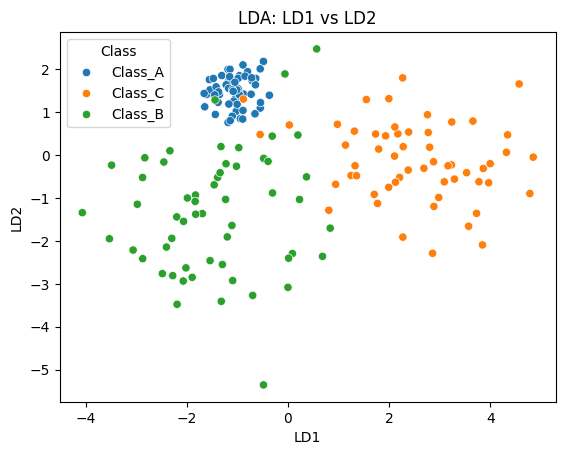

In [ ]:
lda_df = pd.DataFrame(X_train_lda, columns=['LD1', 'LD2'])
lda_df['Class'] = y_train.values

sns.scatterplot(data=lda_df, x='LD1', y='LD2', hue='Class')
plt.title("LDA: LD1 vs LD2")
plt.show()

In [ ]:
print("Explained variance ratio:")
print(lda.explained_variance_ratio_)

print("Total explained variance:")
print(sum(lda.explained_variance_ratio_))

Explained variance ratio:
[0.70480905 0.29519095]
Total explained variance:
1.0


In [ ]:
def evaluate_model(X_train, X_test, y_train, y_test):

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='macro'))
    print("Recall:", recall_score(y_test, y_pred, average='macro'))
    print("F1 Score:", f1_score(y_test, y_pred, average='macro'))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

print("Using Original Features:")
evaluate_model(X_train_scaled, X_test_scaled, y_train, y_test)

print("\nUsing 2 LDA Components:")
evaluate_model(X_train_lda, X_test_lda, y_train, y_test)

Using Original Features:
Accuracy: 0.9166666666666666
Precision: 0.9249762583095916
Recall: 0.9166666666666666
F1 Score: 0.9152272381820946
Confusion Matrix:
[[24  0  0]
 [ 1 19  4]
 [ 1  0 23]]

Using 2 LDA Components:
Accuracy: 0.9166666666666666
Precision: 0.9249762583095916
Recall: 0.9166666666666666
F1 Score: 0.9152272381820946
Confusion Matrix:
[[24  0  0]
 [ 1 19  4]
 [ 1  0 23]]


In [ ]:
lda1 = LinearDiscriminantAnalysis(n_components=1)

X_train_lda1 = lda1.fit_transform(X_train_scaled, y_train)
X_test_lda1 = lda1.transform(X_test_scaled)

print("Training shape:", X_train_lda1.shape)
print("Testing shape:", X_test_lda1.shape)

print("Classification using 1 LDA component:")
evaluate_model(X_train_lda1, X_test_lda1, y_train, y_test)

Training shape: (168, 1)
Testing shape: (72, 1)
Classification using 1 LDA component:
Accuracy: 0.6805555555555556
Precision: 0.6672839506172838
Recall: 0.6805555555555555
F1 Score: 0.6714018940909697
Confusion Matrix:
[[15  9  0]
 [ 9 11  4]
 [ 1  0 23]]


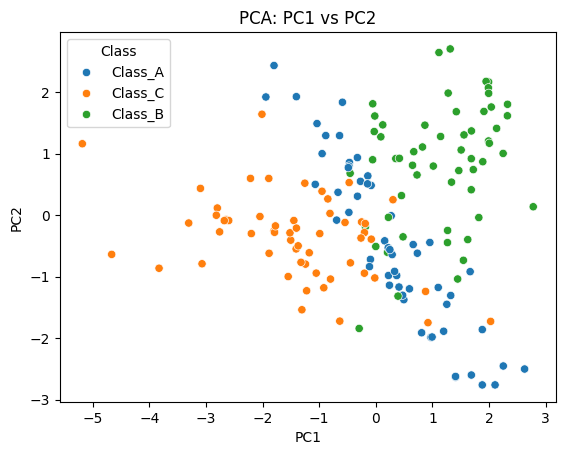

PCA explained variance ratio:
[0.37788802 0.23996096]
Total explained variance:
0.6178489799306565


In [ ]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
pca_df['Class'] = y_train.values

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Class')
plt.title("PCA: PC1 vs PC2")
plt.show()

print("PCA explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total explained variance:")
print(sum(pca.explained_variance_ratio_))